# Decorrelation Analysis: Station Density Comparison

This notebook analyzes the effect of different station density on the resulting decorrelation scale analysis result. We base the main analysis logic on `08_Decorrelation_Analysis_v3.ipynb`, and compare the results between four bays:
- Tokyo Bay
- Ise Bay
- Osaka Bay
- Hiroshima Bay

**Methodology**:
1. Load the unified dataset.
2. Iterate through each of the four bays, filtering the data to Summer Bottom layer observations.
3. Calculate station density (Stations per $km^2$ based on convex hull area).
4. Perform the decorrelation analysis using a Gaussian decay model with offset.
5. Compare the resulting decorrelation scales across the bays and analyze their relationship with station density.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd
from scipy.spatial.distance import cdist
from scipy.optimize import curve_fit
from scipy import stats
from scipy.spatial import ConvexHull
from pathlib import Path
import sys
import warnings

warnings.filterwarnings('ignore')

# Add project root to sys.path
current_dir = Path(os.getcwd()).resolve()
project_root = current_dir.parent
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from utils.paths import ProjectPaths

# Set visual style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

## 1. Define Regions and Parameters

In [2]:
bays = {
    'Tokyo Bay': {'filter_col': 'watermass_name', 'filter_val': 'Tokyo Bay'},
    'Ise Bay': {'filter_col': 'watermass_name', 'filter_val': 'Ise Bay'},
    'Osaka Bay': {'filter_col': 'division', 'filter_val': 'Osaka Bay'},
    'Hiroshima Bay': {'filter_col': 'division', 'filter_val': 'Hiroshima Bay'}
}

# Parameters matching 08_Decorrelation_Analysis_v3.ipynb
min_periods = 15
r_crit_alpha = 0.01
distance_cutoff_km = 100
subset_dir = str(ProjectPaths.get_subset_dir('Summer', 'bottom'))

## 2. Core Functions

In [3]:
def gaussian_model_with_offset(x, A, dx):
    """Gaussian decay with offset, constrained: A + B = 1"""
    B = 1 - A
    return A * np.exp(-(x / dx)**2) + B

def calculate_r_crit(n, alpha=0.01):
    """Calculate critical correlation value for significance test."""
    if n < 3:
        return 1.0
    df = n - 2
    t_crit = stats.t.ppf(1 - alpha/2, df)
    r_crit = np.sqrt(t_crit**2 / (t_crit**2 + df))
    return r_crit

def count_neighbors_within_distance(target_station, dist_matrix, max_distance_km=100):
    """Count number of stations within max_distance_km of target_station"""
    distances = dist_matrix.loc[target_station]
    neighbors = distances[(distances > 0) & (distances <= max_distance_km)]
    return len(neighbors)

## 3. Data Loading and Processing per Bay

In [8]:
print("Loading data...")
merged_gdf = gpd.read_feather(ProjectPaths.MERGED_DATA_FILE)

# Load yearly DO data from seasonal subset
subset_path = Path(subset_dir)
yearly_do_df_all = pd.read_csv(subset_path / 'yearly_do_df.csv', index_col=0)
yearly_do_df_all.index = yearly_do_df_all.index.astype(str).str.zfill(8)

bay_results = {}
all_station_results = []

for bay_name, criteria in bays.items():
    print(f"\n--- Processing {bay_name} ---")
    
    # Filter data for the bay
    bay_gdf = merged_gdf[merged_gdf[criteria['filter_col']] == criteria['filter_val']].copy()
    
    # Align DO data with filtered region
    valid_stations = bay_gdf['zettaicode'].unique()
    yearly_do_df = yearly_do_df_all[yearly_do_df_all.index.isin(valid_stations)].copy()
    
    # Get station coordinates
    station_coords = bay_gdf[['zettaicode', 'geometry']].drop_duplicates('zettaicode')
    station_coords = station_coords[station_coords['zettaicode'].isin(yearly_do_df.index)]
    station_coords = station_coords.set_index('zettaicode')
    
    if len(station_coords) < 5:
        print(f"Not enough valid stations in {bay_name} ({len(station_coords)}). Skipping.")
        continue
            
    # Project to UTM Zone 53N for metric distance & area calculation
    stns_utm = gpd.GeoDataFrame(station_coords, geometry='geometry', crs=bay_gdf.crs).to_crs(epsg=32653)
    coords = np.array([(geom.x, geom.y) for geom in stns_utm['geometry']])
    
    # Station Density Calculation
    try:
        hull = ConvexHull(coords)
        hull_area_km2 = hull.volume / 1e6  # .volume gives area for 2D points in scipy ConvexHull
    except Exception as e:
        print(f"Could not calculate convex hull: {e}")
        hull_area_km2 = np.nan
        
    num_stations = len(stns_utm)
    station_density = num_stations / hull_area_km2 if hull_area_km2 > 0 else np.nan
    
    # Distance Matrix
    dist_matrix = cdist(coords, coords) / 1000.0
    dist_matrix_km = pd.DataFrame(dist_matrix, index=stns_utm.index, columns=stns_utm.index)
    
    #Calculate Nearest Neighbor Distances
    # Find minimum distance > 0 for each station in the bay
    nn_distances = dist_matrix_km.replace(0, np.nan).min(axis=1).values
    avg_nn = np.mean(nn_distances)
    median_nn = np.median(nn_distances)

    print(f"Stations: {num_stations}")
    print(f"Avg Nearest Neighbor Dist: {avg_nn:.2f} km")
    print(f"Median Nearest Neighbor Dist: {median_nn:.2f} km")
    print(f"Area: {hull_area_km2:.1f} km2")
    print(f"Density: {station_density:.3f} stations/km2")

    # Decorrelation Analysis
    results_list = []
    for target_station in yearly_do_df.index:
        target_series = yearly_do_df.loc[target_station]
        correlations = yearly_do_df.corrwith(target_series, axis=1, drop=True)
        
        valid_stats = []
        for neighbor in yearly_do_df.index:
            neigh_series = yearly_do_df.loc[neighbor]
            valid_count = pd.concat([target_series, neigh_series], axis=1).dropna().shape[0]
            
            if valid_count >= min_periods:
                if neighbor == target_station:
                    corr_val, dist_val = 1.0, 0.0
                else:
                    corr_val = correlations[neighbor]
                    dist_val = dist_matrix_km.loc[target_station, neighbor]
                
                if not np.isnan(corr_val) and not np.isnan(dist_val) and dist_val <= distance_cutoff_km:
                    valid_stats.append({'dist': dist_val, 'corr': corr_val, 'n': valid_count})
        
        df_fit = pd.DataFrame(valid_stats)
        if len(df_fit) < 5: continue
        
        x_data, y_data = df_fit['dist'].values, df_fit['corr'].values
        
        try:
            popt, pcov = curve_fit(
                gaussian_model_with_offset, x_data, y_data,
                p0=[1.0, 50.0], bounds=([0, 0.001], [2.0, np.inf])
            )
            A_fit, dx_fit_param = popt
            B_fit = 1 - A_fit
            
            n_neighbors_100km = count_neighbors_within_distance(target_station, dist_matrix_km, distance_cutoff_km)
            r_crit = calculate_r_crit(n_neighbors_100km, alpha=r_crit_alpha) if n_neighbors_100km >= 2 else calculate_r_crit(df_fit['n'].mean(), alpha=r_crit_alpha)
            
            inner_val = (r_crit - B_fit) / A_fit
            decorr_scale = dx_fit_param * np.sqrt(-np.log(inner_val)) if (A_fit > 0 and inner_val > 0 and inner_val < 1) else 0.0
            
            residuals = y_data - gaussian_model_with_offset(x_data, *popt)
            ss_res, ss_tot = np.sum(residuals**2), np.sum((y_data - np.mean(y_data))**2)
            r_squared = 1 - (ss_res / ss_tot) if ss_tot != 0 else 0
            
            # Store station-level result
            results_list.append({
                'Bay': bay_name,
                'Station_ID': target_station,
                'Decorrelation_Scale_km': decorr_scale,
                'R_squared': r_squared,
            })
        except Exception:
            pass
            
    df_results = pd.DataFrame(results_list)
    valid_scales = df_results[df_results['Decorrelation_Scale_km'] > 0]['Decorrelation_Scale_km']
    
    bay_results[bay_name] = {
        'num_stations': num_stations,
        'avg_nn_dist' : avg_nn,
        'median_nn_dist': median_nn,
        'area_km2': hull_area_km2,
        'station_density': station_density,
        'avg_decorr_scale': valid_scales.mean(),
        'median_decorr_scale': valid_scales.median(),
        'std_decorr_scale': valid_scales.std()
    }
    
    all_station_results.extend(results_list)

Loading data...

--- Processing Tokyo Bay ---
Stations: 28
Avg Nearest Neighbor Dist: 5.02 km
Median Nearest Neighbor Dist: 4.69 km
Area: 880.6 km2
Density: 0.032 stations/km2

--- Processing Ise Bay ---
Stations: 33
Avg Nearest Neighbor Dist: 6.30 km
Median Nearest Neighbor Dist: 6.02 km
Area: 2153.0 km2
Density: 0.015 stations/km2

--- Processing Osaka Bay ---
Stations: 10
Avg Nearest Neighbor Dist: 10.20 km
Median Nearest Neighbor Dist: 8.51 km
Area: 834.0 km2
Density: 0.012 stations/km2

--- Processing Hiroshima Bay ---
Stations: 8
Avg Nearest Neighbor Dist: 9.41 km
Median Nearest Neighbor Dist: 9.39 km
Area: 439.7 km2
Density: 0.018 stations/km2


## 4. Summary and Comparison

In [9]:
# Bay-level summary
summary_df = pd.DataFrame.from_dict(bay_results, orient='index')
display(summary_df)

# Station-level results
all_results_df = pd.DataFrame(all_station_results)

# Filter out failed fits (0.0) for plotting
plot_df = all_results_df[all_results_df['Decorrelation_Scale_km'] > 0]

,num_stations,avg_nn_dist,median_nn_dist,area_km2,station_density,avg_decorr_scale,median_decorr_scale,std_decorr_scale
Tokyo Bay,28,5.019487,4.687143,880.565614,0.031798,5.740963,4.861708,3.339147
Ise Bay,33,6.299797,6.021640,2153.032401,0.015327,7.048572,6.742844,3.076195
Osaka Bay,10,10.195476,8.509493,833.967829,0.011991,3.462445,3.757980,2.851488
Hiroshima Bay,8,9.410301,9.386658,439.673702,0.018195,2.936888,3.285903,2.046217


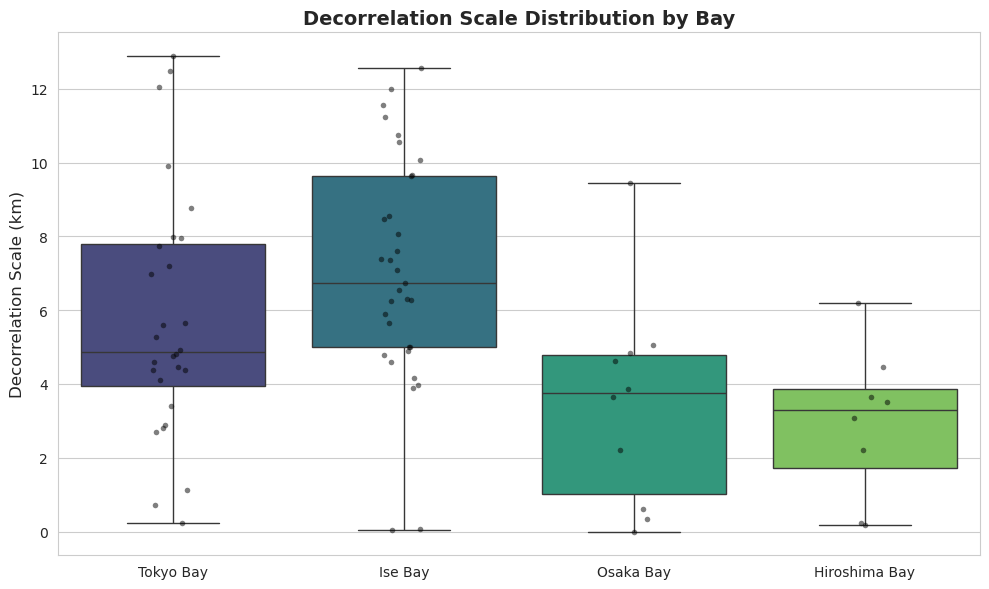

In [10]:
# Visualizing Decorrelation Scales across Bays
plt.figure(figsize=(10, 6))
sns.boxplot(data=plot_df, x='Bay', y='Decorrelation_Scale_km', palette='viridis')
sns.stripplot(data=plot_df, x='Bay', y='Decorrelation_Scale_km', color='black', alpha=0.5, size=4)
plt.title('Decorrelation Scale Distribution by Bay', fontsize=14, fontweight='bold')
plt.ylabel('Decorrelation Scale (km)', fontsize=12)
plt.xlabel('')
plt.tight_layout()
plt.show()

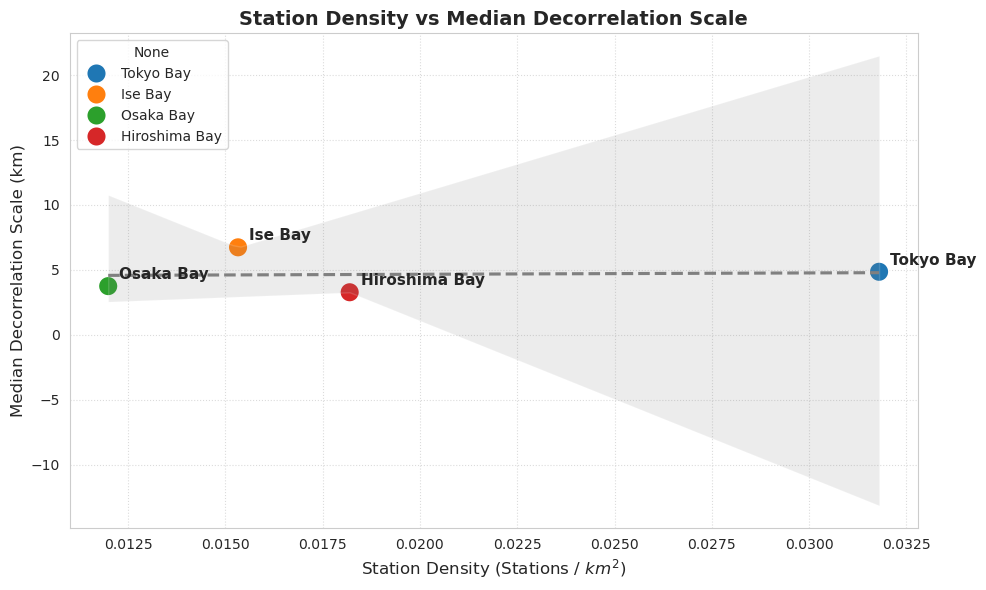

In [11]:
# Visualizing relationship between Station Density and Decorrelation Scale
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=summary_df, 
    x='station_density', 
    y='median_decorr_scale', 
    hue=summary_df.index, 
    s=200, 
    palette='tab10'
)

# Add labels
for i, row in summary_df.iterrows():
    plt.annotate(
        i, 
        (row['station_density'], row['median_decorr_scale']),
        xytext=(8, 5), 
        textcoords='offset points',
        fontsize=11,
        fontweight='bold'
    )

# Trendline
if len(summary_df.dropna()) > 1:
    sns.regplot(
        data=summary_df, 
        x='station_density', 
        y='median_decorr_scale', 
        scatter=False, 
        color='gray', 
        line_kws={'linestyle': '--'}
    )

plt.title('Station Density vs Median Decorrelation Scale', fontsize=14, fontweight='bold')
plt.xlabel('Station Density (Stations / $km^2$)', fontsize=12)
plt.ylabel('Median Decorrelation Scale (km)', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()